# NB\_C08: Closing the Loop - Predicted vs Observed Cognitive Change

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C08_Closing_the_Loop.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 9 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.14 and GPT-5.4

---

## Talk Framing

**One-sentence takeaway:** can a mechanics-informed connectome identify
which cognitive domains are most vulnerable after surgery, and where the
patient does better or worse than the structural model alone would
predict?

## Objectives

- translate mechanics-induced perturbation into domain-level structural risk
- compare predicted vulnerability with observed postoperative cognition
- distinguish agreement, resilience, and mismatch in one figure
- show why psychosocial context matters for the digital twin concept

**Prerequisites:** [NB\_C02](NB_C02_Clinical_Cognitive_Data.ipynb), [NB\_C07](NB_C07_Neural_Dynamics.ipynb)  
**Next:** [NB\_C09](NB_C09_Synthesis_Perspectives.ipynb) (synthesis)

---
## 1. The Validation Question

The central question is simple:

> **Does the mechanically informed connectome identify which cognitive
> domains are most vulnerable to postoperative change?**

This is a **single-patient proof-of-concept**, not a model of absolute
cognition. We compare:

- **Predicted vulnerability**: mechanics-induced loss of structural
  connectivity in domain-relevant parcels from NB\_C07
- **Observed change**: direction-aligned postoperative CANTAB change from
  NB\_C02, where positive values indicate improvement and negative
  values indicate decline

For the main figure, the x-axis is **predicted vulnerability** and the
y-axis is **observed cognitive change**.

| Zone | Predicted vulnerability | Observed change | Interpretation |
|------|--------------------------|-----------------|----------------|
| Upper-right | High | Improved | Resilience / plasticity |
| Lower-right | High | Declined | Model-supported deficit |
| Upper-left | Low | Improved | Expected preservation |
| Lower-left | Low | Declined | Model miss / extra-structural factors |

**Presentation cue:** the point is not only whether the model is right,
but whether it helps separate expected decline, preserved function, and
clinically interesting mismatch.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.io import loadmat
import nibabel as nib
import pandas as pd
from IPython.display import display
import json
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT  = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_PROJ = REPO_ROOT / 'derivatives'
REG_DIR    = DERIV_PROJ / 'registered_t1w' / 'sub-PAT16'
LONG_DIR   = REG_DIR / 'longitudinal'
CONN_DIR   = DERIV_PROJ / 'connectivity' / 'sub-PAT16'
TVB_DIR    = BIDS_ROOT / 'derivatives' / 'TVB' / 'sub-PAT16'
FIG_DIR    = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

DK68_NAMES_LH = [
    'bankssts','caudalanteriorcingulate','caudalmiddlefrontal',
    'cuneus','entorhinal','fusiform','inferiorparietal',
    'inferiortemporal','isthmuscingulate','lateraloccipital',
    'lateralorbitofrontal','lingual','medialorbitofrontal',
    'middletemporal','parahippocampal','paracentral',
    'parsopercularis','parsorbitalis','parstriangularis',
    'pericalcarine','postcentral','posteriorcingulate',
    'precentral','precuneus','rostralanteriorcingulate',
    'rostralmiddlefrontal','superiorfrontal','superiorparietal',
    'superiortemporal','supramarginal','frontalpole',
    'temporalpole','transversetemporal','insula']
DK68_NAMES = [f'lh-{n}' for n in DK68_NAMES_LH] + \
             [f'rh-{n}' for n in DK68_NAMES_LH]
N_REGIONS = 68

LH_LABEL_IDS = [1001,1002,1003,1005,1006,1007,1008,1009,1010,1011,
                1012,1013,1014,1015,1016,1017,1018,1019,1020,1021,
                1022,1023,1024,1025,1026,1027,1028,1029,1030,1031,
                1032,1033,1034,1035]
RH_LABEL_IDS = [lid + 1000 for lid in LH_LABEL_IDS]
DK68_LABEL_IDS = LH_LABEL_IDS + RH_LABEL_IDS

In [2]:
# Reproduce the coupling from NB_C07 to get SC_coupled
sc_mat_path = TVB_DIR / 'ses-preop' / 'SCthrAn.mat'
if sc_mat_path.exists():
    sc_data = loadmat(str(sc_mat_path))
    for _k in ('SC_thr', 'SCthrAn', 'SC', 'weights'):
        if _k in sc_data:
            SC_pre = sc_data[_k].astype(float); break
    else:
        for _k, _v in sc_data.items():
            if isinstance(_v, np.ndarray) and _v.ndim == 2 and _v.shape[0] == _v.shape[1]:
                SC_pre = _v.astype(float); break
else:
    SC_pre = np.load(str(CONN_DIR / 'ses-preop' / 'sc_sift2.npy'))[:N_REGIONS, :N_REGIONS]

SC_pre_norm = SC_pre / SC_pre.max() if SC_pre.max() > 0 else SC_pre

fem_impr_vol = np.asarray(nib.load(str(LONG_DIR / 'fem_displacement_improved.nii.gz')).dataobj).astype(np.float32)
aseg_vol = np.asarray(nib.load(str(REG_DIR / 'ses-postop' / 'aparc+aseg_space-T1w.nii.gz')).dataobj).astype(np.int32)

roi_disp = np.zeros(N_REGIONS)
for idx, label_id in enumerate(DK68_LABEL_IDS):
    mask = (aseg_vol == label_id) & (fem_impr_vol > 0)
    if mask.sum() > 0:
        roi_disp[idx] = fem_impr_vol[mask].mean()

d_max = roi_disp.max()
d_norm = roi_disp / max(d_max, 1e-6)

alpha_sc = 2.0
SC_coupled = SC_pre_norm.copy()
for i in range(N_REGIONS):
    for j in range(N_REGIONS):
        strain_ij = (d_norm[i] + d_norm[j]) / 2.0
        SC_coupled[i, j] *= np.exp(-alpha_sc * strain_ij)

# Load CANTAB data
sessions_tsv = BIDS_ROOT / 'sub-PAT16' / 'sub-PAT16_sessions.tsv'
df_ses = pd.read_csv(sessions_tsv, sep='\t', index_col='session_id')

cantab_metrics = {
    'MOT latency (ms)':     ('mot_latency_mean',  'Motor',              'lower_better'),
    'RTI simple RT (ms)':   ('rti_simple_rt_mean', 'Processing speed',  'lower_better'),
    'RTI 5-choice RT (ms)': ('rti_five_rt',        'Attention / speed', 'lower_better'),
    'RVP A\' (signal det)': ('rvp_a',              'Sustained attention','higher_better'),
    'SOC min-move solved':  ('soc_prob_min_moves', 'Executive function','higher_better'),
    'SSP span length':      ('ssp_span_length',    'Working memory',    'higher_better'),
}

cog_results = []
for label, (col, domain, direction) in cantab_metrics.items():
    if col not in df_ses.columns:
        continue
    try:
        pre  = float(df_ses.loc['ses-preop', col])
        post = float(df_ses.loc['ses-postop', col])
        delta = post - pre
        pct = 100 * delta / abs(pre) if pre != 0 else 0
        improved = delta < 0 if direction == 'lower_better' else delta > 0
        cog_results.append({'Metric': label, 'Domain': domain,
                           'Pre-op': pre, 'Post-op': post,
                           'Delta': delta, '%Delta': pct,
                           'Improved': improved, 'Direction': direction})
    except (ValueError, KeyError):
        pass
df_cog = pd.DataFrame(cog_results)
print(f'Loaded {len(df_cog)} CANTAB metrics')

Loaded 6 CANTAB metrics


---
## 2. Domain Mapping and Predicted Vulnerability

Each cognitive domain is represented by a small, **literature-informed
but intentionally broad** set of DK68 parcels. The goal is not a strict
parcel-to-function claim, but an interpretable estimate of which
large-scale systems are most exposed to the modeled perturbation.

Two choices make the comparison easier to read:

- **Observed change** is direction-aligned, so positive values always
  mean better postoperative performance
- **Predicted vulnerability** combines within-domain SC loss with loss of
  connectivity from the domain to the rest of the brain

Because the mechanics-to-SC coupling contains a free parameter
`alpha_sc`, we also inspect whether the domain ranking remains stable
across a plausible parameter range.

In [3]:
# Domain definitions are intentionally broad and literature-informed.
# The goal is to estimate domain vulnerability, not parcel exclusivity.
domain_specs = {
    'Motor': {
        'parcels': ['precentral', 'paracentral', 'postcentral', 'superiorfrontal'],
        'note': 'sensorimotor execution and response output',
    },
    'Processing speed': {
        'parcels': ['precentral', 'superiorfrontal', 'insula', 'caudalmiddlefrontal'],
        'note': 'response speed and motor preparation',
    },
    'Attention / speed': {
        'parcels': ['superiorfrontal', 'rostralmiddlefrontal', 'caudalmiddlefrontal',
                    'inferiorparietal', 'insula'],
        'note': 'fronto-parietal attentional control',
    },
    'Sustained attention': {
        'parcels': ['caudalmiddlefrontal', 'rostralmiddlefrontal',
                    'inferiorparietal', 'precuneus'],
        'note': 'distributed vigilance network',
    },
    'Executive function': {
        'parcels': ['superiorfrontal', 'caudalmiddlefrontal',
                    'parsopercularis', 'parstriangularis', 'insula'],
        'note': 'prefrontal cognitive control',
    },
    'Working memory': {
        'parcels': ['caudalmiddlefrontal', 'rostralmiddlefrontal', 'superiorparietal',
                    'inferiorparietal', 'precuneus', 'lateraloccipital'],
        'note': 'fronto-parietal maintenance and manipulation',
    },
}

n_use = min(N_REGIONS, len(DK68_NAMES))
dk_lookup = {}
for idx, full_name in enumerate(DK68_NAMES[:n_use]):
    _, parcel = full_name.split('-', 1)
    dk_lookup.setdefault(parcel, []).append(idx)

strain_matrix = (d_norm[:, None] + d_norm[None, :]) / 2.0


def compute_domain_metrics(alpha):
    sc_alpha = SC_pre_norm * np.exp(-alpha * strain_matrix)
    rows = []
    for domain, spec in domain_specs.items():
        indices = sorted({
            idx
            for parcel in spec['parcels']
            for idx in dk_lookup.get(parcel, [])
        })
        if not indices:
            continue

        within_pre = SC_pre_norm[np.ix_(indices, indices)].mean()
        within_post = sc_alpha[np.ix_(indices, indices)].mean()
        outbound_pre = SC_pre_norm[indices, :].mean()
        outbound_post = sc_alpha[indices, :].mean()

        within_loss_pct = 100 * (within_pre - within_post) / (within_pre + 1e-10)
        outbound_loss_pct = 100 * (outbound_pre - outbound_post) / (outbound_pre + 1e-10)

        rows.append({
            'Domain': domain,
            'N parcels': len(indices),
            'Within-domain SC loss (%)': within_loss_pct,
            'Outbound SC loss (%)': outbound_loss_pct,
            'Predicted vulnerability (%)': 0.4 * within_loss_pct + 0.6 * outbound_loss_pct,
            'Mean displacement (mm)': roi_disp[indices].mean(),
            'Mapping note': spec['note'],
        })
    return pd.DataFrame(rows), sc_alpha


alpha_sc = 2.0
domain_summary, SC_coupled = compute_domain_metrics(alpha_sc)

df_cog = df_cog.copy()
df_cog['Observed change (%)'] = df_cog.apply(
    lambda row: -row['%Delta'] if row['Direction'] == 'lower_better' else row['%Delta'],
    axis=1,
)

domain_summary = domain_summary.merge(
    df_cog[['Domain', 'Metric', 'Observed change (%)', 'Improved']],
    on='Domain', how='left'
)

alpha_grid = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
sensitivity_rows = []
for alpha in alpha_grid:
    alpha_summary, _ = compute_domain_metrics(alpha)
    alpha_summary['alpha_sc'] = alpha
    sensitivity_rows.append(alpha_summary[['Domain', 'alpha_sc', 'Predicted vulnerability (%)']])

domain_sensitivity = pd.concat(sensitivity_rows, ignore_index=True)
sensitivity_stats = (
    domain_sensitivity.groupby('Domain')['Predicted vulnerability (%)']
    .agg(['min', 'max', 'std'])
    .rename(columns={
        'min': 'Vulnerability min (%)',
        'max': 'Vulnerability max (%)',
        'std': 'Vulnerability sd (%)',
    })
    .reset_index()
)

domain_summary = (
    domain_summary
    .merge(sensitivity_stats, on='Domain', how='left')
    .sort_values('Predicted vulnerability (%)', ascending=False)
    .reset_index(drop=True)
)

vulnerability_threshold = 10.0
change_threshold = 5.0


def classify_domain(row):
    vulnerable = row['Predicted vulnerability (%)'] >= vulnerability_threshold
    declined = row['Observed change (%)'] <= -change_threshold
    improved = row['Observed change (%)'] >= change_threshold
    if vulnerable and declined:
        return 'Model-supported deficit'
    if vulnerable and improved:
        return 'Resilience / plasticity'
    if (not vulnerable) and declined:
        return 'Model miss / extra-structural'
    return 'Expected preservation'


def summarize_stability(row):
    spread = row['Vulnerability max (%)'] - row['Vulnerability min (%)']
    if spread < 6:
        return 'High'
    if spread < 12:
        return 'Moderate'
    return 'Low'


domain_summary['Interpretation'] = domain_summary.apply(classify_domain, axis=1)
domain_summary['Stability'] = domain_summary.apply(summarize_stability, axis=1)
domain_summary['Sensitivity range (%)'] = domain_summary.apply(
    lambda row: f"{row['Vulnerability min (%)']:.1f}-{row['Vulnerability max (%)']:.1f}",
    axis=1,
)
domain_summary['Rank'] = np.arange(1, len(domain_summary) + 1)

domain_disruption = dict(zip(domain_summary['Domain'], domain_summary['Predicted vulnerability (%)']))
domain_displacement = dict(zip(domain_summary['Domain'], domain_summary['Mean displacement (mm)']))

summary_pub = domain_summary[
    [
        'Rank',
        'Domain',
        'Predicted vulnerability (%)',
        'Observed change (%)',
        'Mean displacement (mm)',
        'Sensitivity range (%)',
        'Stability',
        'Interpretation',
    ]
].rename(columns={
    'Predicted vulnerability (%)': 'Predicted vuln. (%)',
    'Observed change (%)': 'Observed change (%)',
    'Mean displacement (mm)': 'Mean disp. (mm)',
    'Sensitivity range (%)': 'alpha range (%)',
    'Interpretation': 'Zone',
})

print(f'Domain-level vulnerability summary (alpha_sc = {alpha_sc:.1f})')
print('Higher predicted vulnerability indicates greater model-predicted postoperative risk.')

Domain-level vulnerability summary (alpha_sc = 2.0)
Higher predicted vulnerability indicates greater model-predicted postoperative risk.


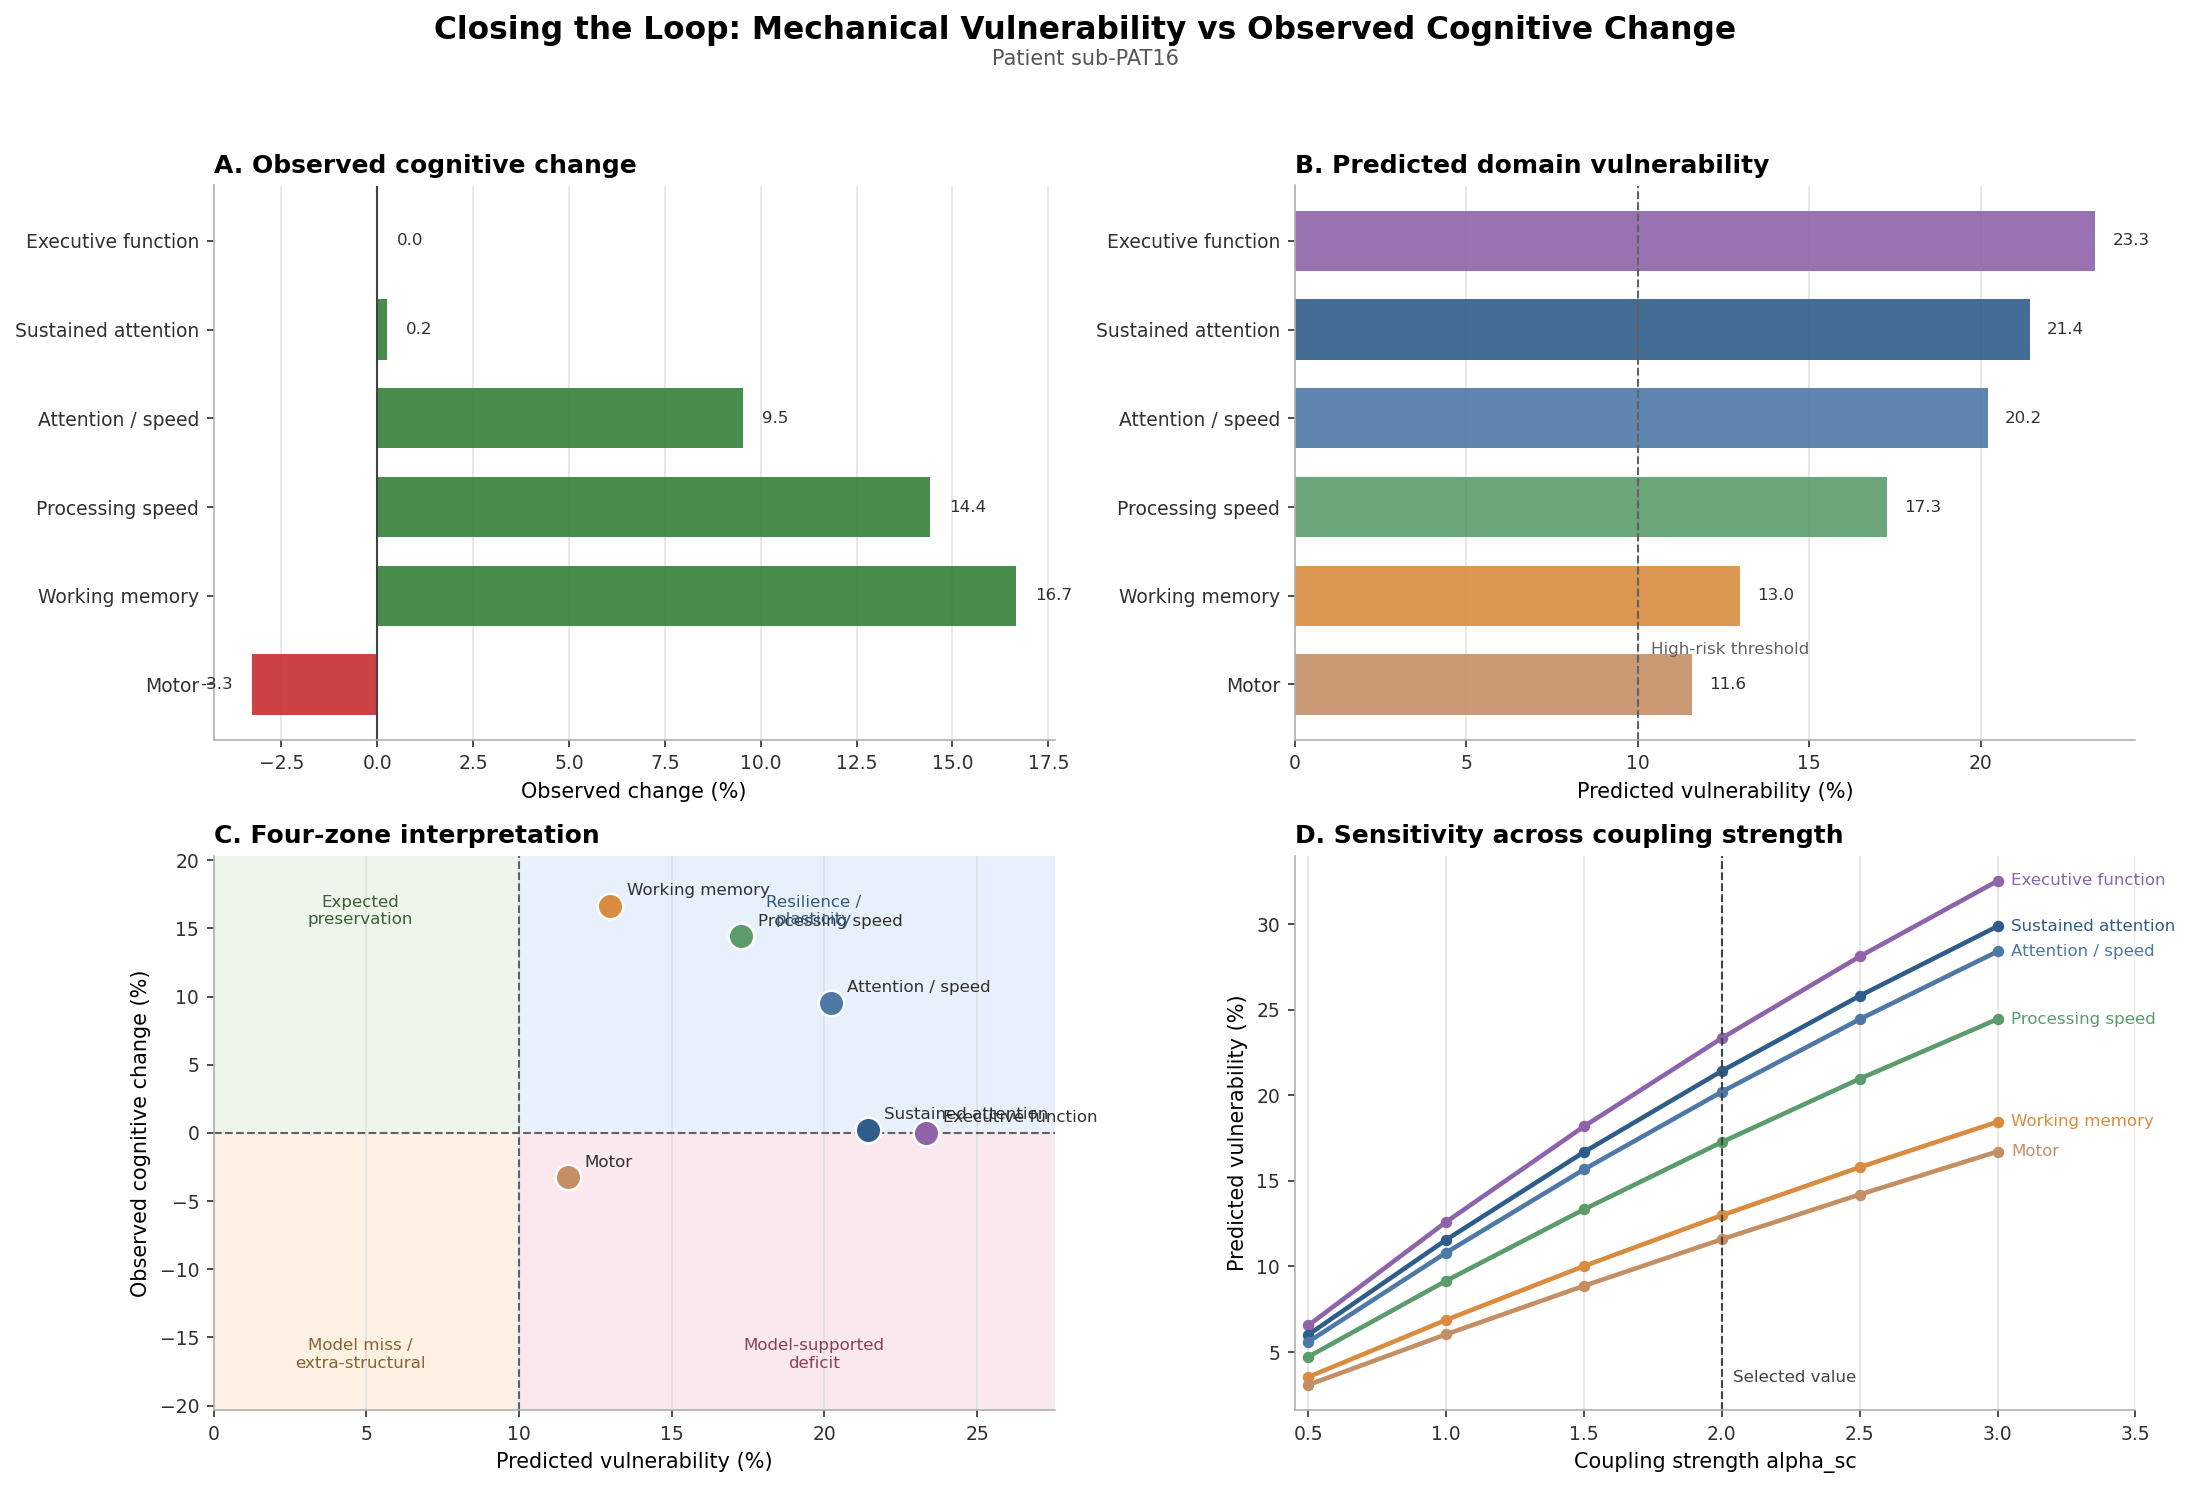

In [4]:
plot_df = domain_summary.dropna(subset=['Observed change (%)']).copy()
plot_df = plot_df.sort_values('Predicted vulnerability (%)', ascending=False)

domain_colors = {
    'Motor': '#C58F65',
    'Processing speed': '#5B9B6C',
    'Attention / speed': '#4E79A7',
    'Sustained attention': '#2F5D8A',
    'Executive function': '#8E63A9',
    'Working memory': '#D98C3F',
}

zone_colors = {
    'Expected preservation': '#EEF6EC',
    'Resilience / plasticity': '#E8F1FB',
    'Model miss / extra-structural': '#FCF1E3',
    'Model-supported deficit': '#F9E8EE',
}


def style_axis(ax, xgrid=True, ygrid=False):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#B0B0B0')
    ax.spines['bottom'].set_color('#B0B0B0')
    ax.tick_params(colors='#303030', labelsize=9)
    if xgrid:
        ax.grid(axis='x', color='#D9D9D9', linewidth=0.8, alpha=0.7)
    if ygrid:
        ax.grid(axis='y', color='#E6E6E6', linewidth=0.8, alpha=0.6)
    ax.set_axisbelow(True)


def add_bar_labels(ax, values, pad=0.5, fmt='{:.1f}'):
    for patch, value in zip(ax.patches, values):
        x = patch.get_width()
        y = patch.get_y() + patch.get_height() / 2
        if value >= 0:
            ax.text(x + pad, y, fmt.format(value), va='center', ha='left', fontsize=8, color='#303030')
        else:
            ax.text(x - pad, y, fmt.format(value), va='center', ha='right', fontsize=8, color='#303030')


fig, axes = plt.subplots(2, 2, figsize=(15.5, 10.5))
fig.suptitle(
    'Closing the Loop: Mechanical Vulnerability vs Observed Cognitive Change',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
fig.text(0.5, 0.952, 'Patient sub-PAT16', ha='center', va='center', fontsize=10, color='#555555')

# Panel A: Observed postoperative cognitive change
ax = axes[0, 0]
obs_colors = ['#2E7D32' if v >= 0 else '#C62828' for v in plot_df['Observed change (%)']]
ax.barh(plot_df['Domain'], plot_df['Observed change (%)'], color=obs_colors, alpha=0.88, height=0.68)
ax.axvline(0, color='#424242', linewidth=1.0)
ax.set_xlabel('Observed change (%)')
ax.set_title('A. Observed cognitive change', loc='left', fontweight='bold')
ax.invert_yaxis()
style_axis(ax)
add_bar_labels(ax, plot_df['Observed change (%)'])

# Panel B: Predicted vulnerability from SC loss
ax = axes[0, 1]
ax.barh(
    plot_df['Domain'],
    plot_df['Predicted vulnerability (%)'],
    color=[domain_colors.get(d, '#999999') for d in plot_df['Domain']],
    alpha=0.9,
    height=0.68,
)
ax.axvline(vulnerability_threshold, color='#616161', linewidth=1.0, linestyle='--')
ax.set_xlabel('Predicted vulnerability (%)')
ax.set_title('B. Predicted domain vulnerability', loc='left', fontweight='bold')
ax.invert_yaxis()
style_axis(ax)
add_bar_labels(ax, plot_df['Predicted vulnerability (%)'])
ax.text(
    vulnerability_threshold + 0.4,
    0.15,
    'High-risk threshold',
    transform=ax.get_xaxis_transform(),
    fontsize=8,
    color='#616161',
    ha='left',
    va='bottom',
)

# Panel C: Four-zone interpretation plot
ax = axes[1, 0]
x_max = max(vulnerability_threshold + 2, plot_df['Predicted vulnerability (%)'].max() * 1.18)
y_lim = max(10, np.abs(plot_df['Observed change (%)']).max() * 1.22)

ax.add_patch(plt.Rectangle((0, 0), vulnerability_threshold, y_lim, facecolor=zone_colors['Expected preservation'], edgecolor='none', zorder=0))
ax.add_patch(plt.Rectangle((vulnerability_threshold, 0), x_max - vulnerability_threshold, y_lim, facecolor=zone_colors['Resilience / plasticity'], edgecolor='none', zorder=0))
ax.add_patch(plt.Rectangle((0, -y_lim), vulnerability_threshold, y_lim, facecolor=zone_colors['Model miss / extra-structural'], edgecolor='none', zorder=0))
ax.add_patch(plt.Rectangle((vulnerability_threshold, -y_lim), x_max - vulnerability_threshold, y_lim, facecolor=zone_colors['Model-supported deficit'], edgecolor='none', zorder=0))

for _, row in plot_df.iterrows():
    domain = row['Domain']
    ax.scatter(
        row['Predicted vulnerability (%)'],
        row['Observed change (%)'],
        s=150,
        color=domain_colors.get(domain, '#999999'),
        edgecolors='white',
        linewidth=1.2,
        zorder=5,
    )
    ax.annotate(
        domain,
        (row['Predicted vulnerability (%)'], row['Observed change (%)']),
        textcoords='offset points',
        xytext=(8, 5),
        fontsize=8,
        color='#303030',
    )

ax.axhline(0, color='#616161', linewidth=1.0, linestyle='--')
ax.axvline(vulnerability_threshold, color='#616161', linewidth=1.0, linestyle='--')
ax.set_xlim(0, x_max)
ax.set_ylim(-y_lim, y_lim)
ax.set_xlabel('Predicted vulnerability (%)')
ax.set_ylabel('Observed cognitive change (%)')
ax.set_title('C. Four-zone interpretation', loc='left', fontweight='bold')
style_axis(ax)

left_x = vulnerability_threshold * 0.48
right_x = vulnerability_threshold + (x_max - vulnerability_threshold) * 0.55
ax.text(left_x, y_lim * 0.80, 'Expected\npreservation', ha='center', va='center', fontsize=8, color='#3D5C3B')
ax.text(right_x, y_lim * 0.80, 'Resilience /\nplasticity', ha='center', va='center', fontsize=8, color='#315A80')
ax.text(left_x, -y_lim * 0.80, 'Model miss /\nextra-structural', ha='center', va='center', fontsize=8, color='#8A6130')
ax.text(right_x, -y_lim * 0.80, 'Model-supported\ndeficit', ha='center', va='center', fontsize=8, color='#8A3F56')

# Panel D: Sensitivity to coupling strength
ax = axes[1, 1]
for domain in plot_df['Domain']:
    sens = domain_sensitivity[domain_sensitivity['Domain'] == domain]
    color = domain_colors.get(domain, '#999999')
    ax.plot(
        sens['alpha_sc'],
        sens['Predicted vulnerability (%)'],
        marker='o',
        linewidth=2.2,
        markersize=4.5,
        color=color,
    )
    last = sens.iloc[-1]
    ax.text(last['alpha_sc'] + 0.05, last['Predicted vulnerability (%)'], domain, color=color, fontsize=8, va='center')

ax.axvline(alpha_sc, color='#424242', linestyle='--', linewidth=1.0)
ax.set_xlim(alpha_grid.min() - 0.05, alpha_grid.max() + 0.5)
ax.set_xlabel('Coupling strength alpha_sc')
ax.set_ylabel('Predicted vulnerability (%)')
ax.set_title('D. Sensitivity across coupling strength', loc='left', fontweight='bold')
style_axis(ax)
ax.text(alpha_sc + 0.04, 0.05, 'Selected value', transform=ax.get_xaxis_transform(), fontsize=8, color='#424242')

fig.tight_layout(rect=[0.03, 0.04, 0.98, 0.94])
fig.savefig(FIG_DIR / 'figC08_01_closing_the_loop.png', bbox_inches='tight')
plt.show()

---
## 3. Interpretation, Robustness, and Psychosocial Context

The four-zone plot is best read as a **structured interpretation aid**,
not as a binary pass/fail test.

- **Model-supported deficit**: the patient declined in a domain the model
  also marked as vulnerable
- **Resilience / plasticity**: the model predicted vulnerability, but the
  observed outcome remained stable or improved
- **Expected preservation**: low predicted vulnerability and no decline
- **Model miss / extra-structural factors**: decline without strong
  structural vulnerability in the current model representation

### Why the sensitivity panel matters

A single value of `alpha_sc` should not carry the whole argument. Domains
that remain high-risk across the parameter range are more convincing than
domains whose ranking changes substantially with small parameter shifts.

### Psychosocial modulation is part of the explanation

From NB\_C02, PAT16's psychosocial profile changed substantially:

- STAI anxiety: 36 $\to$ 30 (improved)
- PSWQ worry: 54 $\to$ 61 (worsened)
- ERQ reappraisal: 24 $\to$ 14 (substantially reduced)
- UCLA loneliness: 40 $\to$ 50 (increased)
- Employment: employed $\to$ sick leave

These changes plausibly affect attention, executive function, working
memory, fatigue, and task engagement. They should therefore not be used
simply to explain away mismatches. Rather, they indicate what the next
version of the digital twin should include: structural, functional, and
psychosocial state variables.

### Main caveat

The parcel-to-domain mapping is still a simplified approximation. A
stronger next version would use hemisphere-aware network weights,
uncertainty estimates, and normative models of cognitive change.

In [5]:
top_risk = domain_summary.iloc[0]
top_decline = domain_summary.sort_values('Observed change (%)').iloc[0]
resilient_domains = domain_summary[
    domain_summary['Interpretation'] == 'Resilience / plasticity'
].sort_values('Predicted vulnerability (%)', ascending=False)

top_resilience = resilient_domains.iloc[0] if not resilient_domains.empty else None

print('Talk highlights')
print(f"- Highest predicted vulnerability: {top_risk['Domain']} ({top_risk['Predicted vulnerability (%)']:.1f}%)")
print(f"- Largest observed decline: {top_decline['Domain']} ({top_decline['Observed change (%)']:.1f}%)")
if top_resilience is not None:
    print(
        f"- Strongest resilience signal: {top_resilience['Domain']} "
        f"(vulnerability {top_resilience['Predicted vulnerability (%)']:.1f}%, "
        f"observed change {top_resilience['Observed change (%)']:.1f}%)"
    )

print('\nTable 1. Domain-level summary of predicted vulnerability and observed cognitive change')
print(f'Selected coupling strength: alpha_sc = {alpha_sc:.1f}')

display(
    summary_pub.style
    .hide(axis='index')
    .format({
        'Predicted vuln. (%)': '{:.1f}',
        'Observed change (%)': '{:.1f}',
        'Mean disp. (mm)': '{:.3f}',
    })
    .set_properties(**{'text-align': 'left'})
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', 'bold'), ('border-bottom', '1px solid #999')]},
        {'selector': 'td', 'props': [('border-bottom', '1px solid #E0E0E0')]},
        {'selector': 'caption', 'props': [('caption-side', 'bottom'), ('text-align', 'left'), ('color', '#555')]},
    ])
    .background_gradient(subset=['Predicted vuln. (%)'], cmap='Oranges')
    .background_gradient(subset=['Observed change (%)'], cmap='RdYlGn')
    .set_caption(
        'Predicted vulnerability is a weighted combination of within-domain and outbound SC loss. '
        'Stability summarizes how much the vulnerability estimate varies across the alpha_sc sensitivity range.'
    )
)

print('\nInterpretation thresholds:')
print(f'  high vulnerability >= {vulnerability_threshold:.1f}%')
print(f'  decline <= -{change_threshold:.1f}%   improvement >= +{change_threshold:.1f}%')

Talk highlights
- Highest predicted vulnerability: Executive function (23.3%)
- Largest observed decline: Motor (-3.3%)
- Strongest resilience signal: Attention / speed (vulnerability 20.2%, observed change 9.5%)

Table 1. Domain-level summary of predicted vulnerability and observed cognitive change
Selected coupling strength: alpha_sc = 2.0


Rank,Domain,Predicted vuln. (%),Observed change (%),Mean disp. (mm),alpha range (%),Stability,Zone
1,Executive function,23.3,0.0,0.070,6.6-32.5,Low,Expected preservation
2,Sustained attention,21.4,0.2,0.055,6.0-29.9,Low,Expected preservation
3,Attention / speed,20.2,9.5,0.054,5.6-28.4,Low,Resilience / plasticity
4,Processing speed,17.3,14.4,0.047,4.7-24.5,Low,Resilience / plasticity
5,Working memory,13.0,16.7,0.041,3.5-18.4,Low,Resilience / plasticity
6,Motor,11.6,-3.3,0.020,3.1-16.7,Low,Expected preservation



Interpretation thresholds:
  high vulnerability >= 10.0%
  decline <= -5.0%   improvement >= +5.0%


---
## Summary

This notebook closes the loop by comparing a **patient-specific,
mechanics-informed prediction of domain vulnerability** with the
patient's **observed postoperative cognitive change**.

In the context of the glioma brain digital twin, that comparison matters
because it turns the modeling chain developed in the earlier notebooks
into a clinically interpretable test:

1. tissue deformation from the postoperative mechanics model perturbs the
   structural connectome
2. that perturbation is summarized as domain-level vulnerability in
   cognitively relevant DK68 parcel sets
3. the predicted vulnerability is compared with direction-aligned CANTAB
   change, so improvement and decline can be interpreted consistently

For talk delivery, the central message is:

> **A mechanics-informed structural twin is already clinically useful if
> it can identify domains at risk, distinguish preserved from vulnerable
> systems, and make model-data mismatches visible rather than hiding
> them.**

### What is evidence-based here

This notebook supports several concrete claims.

- It demonstrates a **falsifiable patient-specific workflow** linking
  mechanics, structural connectivity, and cognition.
- It shows that the prediction can be expressed at the level of
  **cognitive domains**, which is more clinically meaningful than a raw
  connectome perturbation alone.
- It makes clear that agreement is only one outcome of interest.
  **Resilience / plasticity** and **model miss / extra-structural
  factors** are also informative outcomes because they expose limits of a
  purely structural model.
- The added sensitivity analysis shows whether a domain remains relatively
  high-risk across plausible values of `alpha_sc`, giving at least a
  first-pass indication of robustness.

### What this notebook does not prove

This is still a **single-patient proof-of-concept**. It does not yet
establish predictive generalization, causal specificity, or clinical
readiness. The parcel-to-domain mapping is simplified, the coupling from
mechanics to SC remains parameterized, and the observed cognitive change
is influenced by factors beyond structural injury alone.

That limitation is especially important in glioma, where postoperative
outcome may reflect not only tissue displacement and disconnection, but
also plastic reorganisation, treatment effects, fatigue, emotional
state, social context, and return-to-work pressures.

### Why this matters for the glioma brain digital twin

The value of the glioma brain digital twin is not that it provides a
perfect explanation of cognition from structure alone. Its value is that
it offers a **testable and interpretable framework** in which different
sources of evidence can be brought together.

In this notebook, the twin becomes more than a biomechanical or network
simulation. It becomes a candidate **clinical reasoning model**:

- where predicted vulnerability and observed decline align, the model
  supports domain-specific risk
- where vulnerability is high but cognition is preserved, the result
  points toward resilience, compensation, or reorganisation
- where cognition worsens despite low predicted vulnerability, the result
  argues for missing biology or missing state variables in the twin

This is exactly the kind of loop that matters for glioma: a disease in
which local tumour burden, distributed network effects, surgery,
adaptation, and psychosocial burden all interact over time.

### What would strengthen the next version

- patient-specific hemisphere-aware domain mapping
- network-based rather than parcel-list weighting
- uncertainty estimates for the mechanics-to-connectivity coupling
- integration of functional and psychosocial state variables
- multi-patient validation with normative cognitive change models

---

**Next:** [NB\_C09](NB_C09_Synthesis_Perspectives.ipynb) -- Synthesis and mathematical perspectives

---
## Slide-Ready Take-Home Messages

- The structural model does **not** try to explain all cognition; it
  estimates which domains are most vulnerable after the modeled
  perturbation.
- Agreement is useful, but **mismatch is also informative**: it points to
  plasticity, compensation, or variables outside the current model.
- Psychosocial change is not a side note. It is part of what the next
  version of the glioma brain digital twin should model.
- The scientific value here is not only prediction, but a **testable and
  interpretable loop** from mechanics to cognition.

---
## Suggested 60-Second Narration

"This notebook is where the digital twin becomes clinically meaningful.
We start from a mechanics-informed perturbation of the structural
connectome and ask a simple question: which cognitive domains should be
most vulnerable after surgery? We then compare that model-based
vulnerability with the patient's observed postoperative cognitive
change. The important point is not only where the model agrees with the
patient, but also where it does not. High vulnerability with preserved
performance suggests resilience or plasticity. Decline without strong
structural vulnerability suggests missing biology or extra-structural
factors, including psychosocial state. So the notebook does not close
all loops, but it closes the first interpretable one: mechanics to
connectivity to domain-level cognitive risk."